# California Housing Price Prediction

## Project overview

In this project, I build regression models to estimate the **median house value for a California census block group** using the existing project dataset. I compare an ordinary least-squares baseline with Ridge and Lasso regularization, and check whether a few interpretable household ratios improve the results.

**Question:** How well can a simple linear model estimate the block group's median value from its recorded location, housing, population, income, and ocean-proximity attributes?

**Project workflow:** inspect the data ? explore the target and predictors ? split into training and holdout sets ? handle multicollinearity and engineer ratios ? fit preprocessing inside cross-validation pipelines ? tune regularization ? evaluate and inspect residuals.

**Data handling:** The notebook reads `Task 2/housing.csv` with Pandas. It does not download, generate, or overwrite a dataset.

> **Scope note:** This dataset contains area-level median values, not individual home sale prices, and values are capped at $500,001. Results are useful for this assignment's model comparison, not as current property valuations.

## 1. Import libraries

The project uses Pandas and NumPy for working with tabular data, Matplotlib and Seaborn for plots, and scikit-learn for preprocessing, cross-validation, regression, and evaluation.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, KFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

## 2. Load the existing dataset

I load the California Housing CSV already stored beside this notebook. The file is read with Pandas and is not changed. The displayed preview and dimensions are a quick check that the expected local data was selected.

In [2]:
# Find only the CSV already stored in the project.
candidates = [Path("housing.csv"), Path("Task 2") / "housing.csv", Path.cwd().parent / "Task 2" / "housing.csv"]
dataset_path = next((path.resolve() for path in candidates if path.is_file()), None)
if dataset_path is None:
    raise FileNotFoundError("Could not find the existing Task 2/housing.csv file.")
housing = pd.read_csv(dataset_path)
print(f"Dataset: {dataset_path}")
print(f"Shape: {housing.shape[0]:,} rows x {housing.shape[1]} columns")
print(housing.head().to_string(index=False))

Dataset: C:\Users\usms.202300087\Datheon_Machine_Learning_&_Data_Science_Internship\Task 2\housing.csv
Shape: 20,640 rows x 10 columns
 longitude  latitude  housing_median_age  total_rooms  total_bedrooms  population  households  median_income  median_house_value ocean_proximity
   -122.23     37.88                41.0        880.0           129.0       322.0       126.0         8.3252            452600.0        NEAR BAY
   -122.22     37.86                21.0       7099.0          1106.0      2401.0      1138.0         8.3014            358500.0        NEAR BAY
   -122.24     37.85                52.0       1467.0           190.0       496.0       177.0         7.2574            352100.0        NEAR BAY
   -122.25     37.85                52.0       1274.0           235.0       558.0       219.0         5.6431            341300.0        NEAR BAY
   -122.25     37.85                52.0       1627.0           280.0       565.0       259.0         3.8462            342200.0        NEAR

## 3. Inspect columns, data types, and summary statistics

This step checks the dataset schema and numeric ranges. These checks are important because the target is measured in dollars and the predictors have very different units and scales.

In [3]:
print("Columns:", housing.columns.tolist())
print("\nData types:\n", housing.dtypes.to_string())
print("\nSummary statistics:\n", housing.describe(include="all").round(2).to_string())

Columns: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'median_house_value', 'ocean_proximity']

Data types:
 longitude             float64
latitude              float64
housing_median_age    float64
total_rooms           float64
total_bedrooms        float64
population            float64
households            float64
median_income         float64
median_house_value    float64
ocean_proximity           str

Summary statistics:
         longitude  latitude  housing_median_age  total_rooms  total_bedrooms  population  households  median_income  median_house_value ocean_proximity
count    20640.00  20640.00            20640.00     20640.00        20433.00    20640.00    20640.00       20640.00            20640.00           20640
unique        NaN       NaN                 NaN          NaN             NaN         NaN         NaN            NaN                 NaN               5
top           NaN       NaN     

## 4. Check missing values and duplicate records

Missing predictors can be imputed during model fitting, while rows duplicated in the modeling copy should not count twice. I inspect both issues before building the pipelines and preserve the original DataFrame.

In [4]:
print("Missing values per column:\n", housing.isna().sum().to_string())
print(f"\nTotal missing values: {housing.isna().sum().sum():,}")
print(f"Duplicate records: {housing.duplicated().sum():,}")

Missing values per column:
 longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0

Total missing values: 207
Duplicate records: 0


## 5. Set the target and identify feature types

The prediction target is `median_house_value`. Numeric predictors describe location, housing stock, and income; `ocean_proximity` is categorical and must be encoded before regression.

In [5]:
target = "median_house_value"
if target not in housing.columns:
    raise KeyError(f"Target column {target!r} is missing.")
X_all = housing.drop(columns=target)
y_all = housing[target].astype(float)
numeric_columns_all = X_all.select_dtypes(include=np.number).columns.tolist()
categorical_columns = X_all.select_dtypes(exclude=np.number).columns.tolist()
print(f"Target: {target}")
print(f"Numeric features: {numeric_columns_all}")
print(f"Categorical features: {categorical_columns}")
print(f"Target missing values: {y_all.isna().sum()}")

Target: median_house_value
Numeric features: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income']
Categorical features: ['ocean_proximity']
Target missing values: 0


## 6. Explore the target distribution

The histogram and boxplot show the distribution and possible concentration at the upper end. The target is capped in the source dataset, so predictions near the cap need special caution.

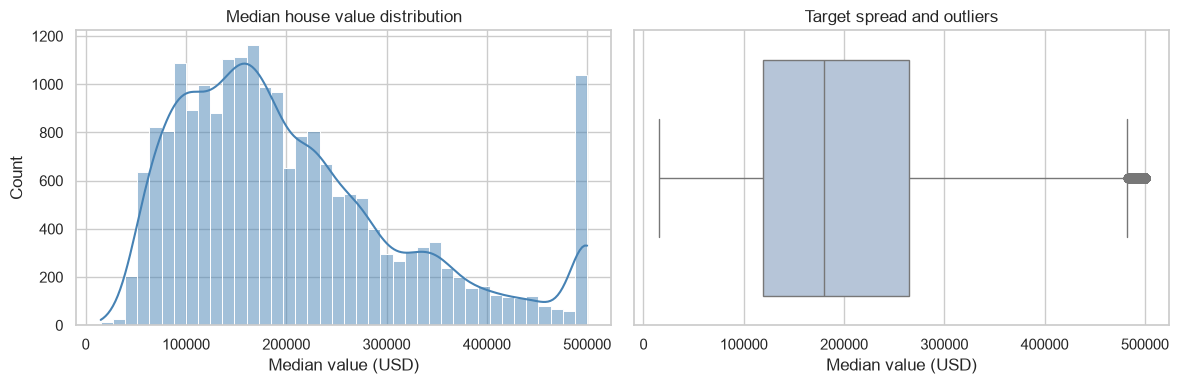

Mean: $206,856; median: $179,700


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(y_all, bins=40, kde=True, ax=axes[0], color="steelblue")
axes[0].set(title="Median house value distribution", xlabel="Median value (USD)")
sns.boxplot(x=y_all, ax=axes[1], color="lightsteelblue")
axes[1].set(title="Target spread and outliers", xlabel="Median value (USD)")
plt.tight_layout(); plt.show()
print(f"Mean: ${y_all.mean():,.0f}; median: ${y_all.median():,.0f}")

## 7. Explore categorical values

The category counts show how observations are distributed across ocean-proximity groups. One-hot encoding later converts the text groups into numeric indicators without assigning them an artificial order.


ocean_proximity counts:
ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5


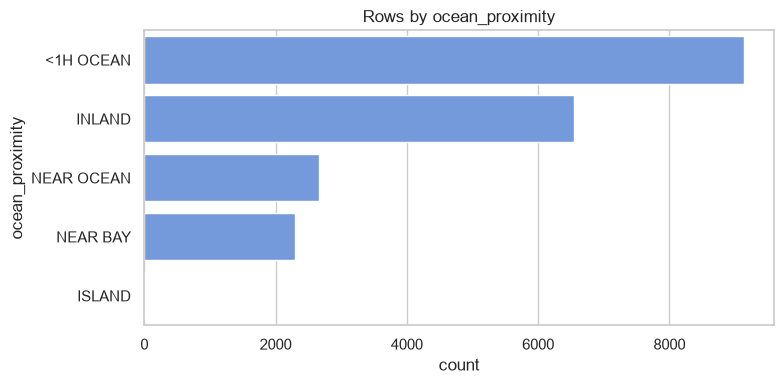

In [7]:
for column in categorical_columns:
    print(f"\n{column} counts:\n{housing[column].value_counts(dropna=False).to_string()}")
    plt.figure(figsize=(8, 4))
    sns.countplot(data=housing, y=column, order=housing[column].value_counts().index, color="cornflowerblue")
    plt.title(f"Rows by {column}"); plt.tight_layout(); plt.show()

## 8. Explore location and house value

The map-like scatter plot places each observation by longitude and latitude and colors it by median value. Spatial patterns can be informative, but this simple linear modeling workflow does not explicitly model geographic neighborhoods.

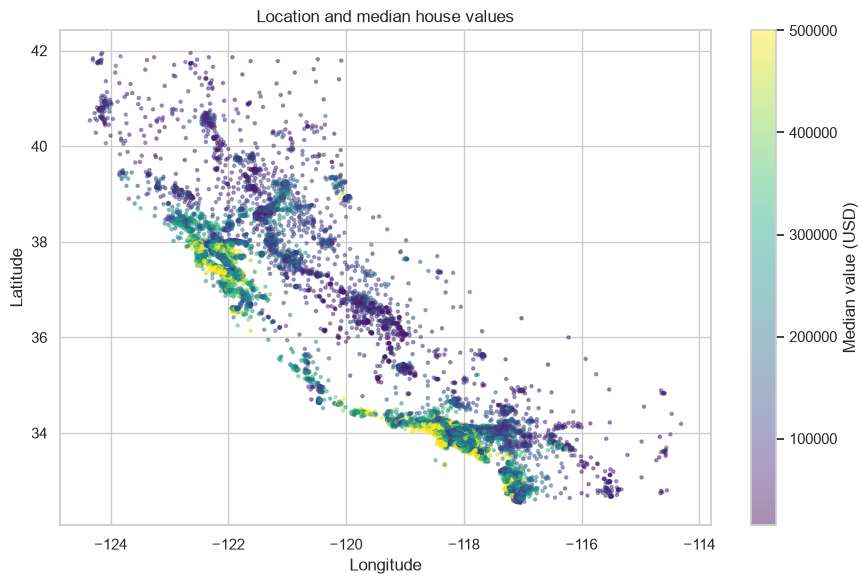

In [8]:
if {"longitude", "latitude"}.issubset(housing.columns):
    plt.figure(figsize=(9, 6))
    points = plt.scatter(housing["longitude"], housing["latitude"], c=y_all, cmap="viridis", s=5, alpha=0.45)
    plt.colorbar(points, label="Median value (USD)")
    plt.title("Location and median house values"); plt.xlabel("Longitude"); plt.ylabel("Latitude")
    plt.tight_layout(); plt.show()

## 9. Correlation analysis and heatmap

The heatmap summarizes pairwise linear correlations among numeric columns, including the target. Correlation helps identify possible redundancy, but it does not prove causation and cannot detect every nonlinear relationship.

Numeric correlations with target:
 median_house_value    1.000000
median_income         0.688075
total_rooms           0.134153
housing_median_age    0.105623
households            0.065843
total_bedrooms        0.049686
population           -0.024650
longitude            -0.045967
latitude             -0.144160


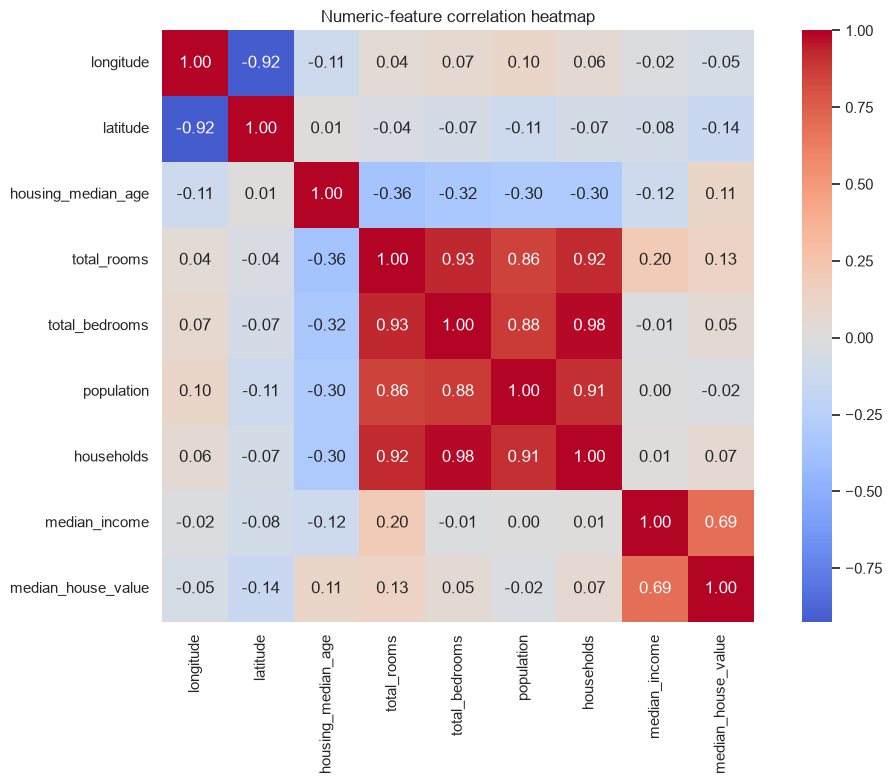

In [9]:
correlation_columns = numeric_columns_all + [target]
correlation_matrix = housing[correlation_columns].corr()
print("Numeric correlations with target:\n", correlation_matrix[target].sort_values(ascending=False).to_string())
plt.figure(figsize=(11, 8))
sns.heatmap(correlation_matrix, cmap="coolwarm", center=0, annot=True, fmt=".2f", square=True)
plt.title("Numeric-feature correlation heatmap"); plt.tight_layout(); plt.show()

## 10. Remove duplicates in the modeling copy and create a holdout split

I create a separate modeling copy so the source data remains untouched. The test set is reserved for final evaluation; it is not used to fit imputers or scalers or to select Ridge/Lasso alpha values.

In [10]:
# Keep `housing` unchanged; clean only the modeling copy.
model_data = housing.drop_duplicates().dropna(subset=[target]).copy()
X = model_data.drop(columns=target)
y = model_data[target].astype(float)
X_train_raw, X_test_raw, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=RANDOM_STATE)
print(f"Modeling rows: {len(model_data):,}; duplicate rows removed: {len(housing) - len(housing.drop_duplicates()):,}")
print(f"Train rows: {len(X_train_raw):,}; test rows: {len(X_test_raw):,}")
print("The test set is held out from preprocessing and alpha selection.")

Modeling rows: 20,640; duplicate rows removed: 0
Train rows: 16,512; test rows: 4,128
The test set is held out from preprocessing and alpha selection.


## 11. Create meaningful engineered features

The added ratios express housing characteristics per household or per room, which can be more interpretable than block-group totals alone. The original columns are retained when they pass the VIF screen, allowing a direct comparison between the baseline and engineered feature sets.

`rooms_per_household` estimates housing space per household; `bedrooms_per_room` describes the bedroom share of a block group's rooms; `population_per_household` estimates average household size. These ratios add interpretable interactions between relevant columns. They are calculated row-by-row, without learning from the test set.

In [11]:
def add_housing_features(frame):
    result = frame.copy()
    result["rooms_per_household"] = result["total_rooms"] / result["households"].replace(0, np.nan)
    result["bedrooms_per_room"] = result["total_bedrooms"] / result["total_rooms"].replace(0, np.nan)
    result["population_per_household"] = result["population"] / result["households"].replace(0, np.nan)
    return result
X_train_eng = add_housing_features(X_train_raw)
X_test_eng = add_housing_features(X_test_raw)
engineered_names = ["rooms_per_household", "bedrooms_per_room", "population_per_household"]
print("Added:", engineered_names)
print("Engineered training shape:", X_train_eng.shape)

Added: ['rooms_per_household', 'bedrooms_per_room', 'population_per_household']
Engineered training shape: (16512, 12)


## 12. Calculate VIF on training features

Variance Inflation Factor (VIF) measures how strongly one numeric predictor can be explained by the others. It is calculated on imputed training data only, so the held-out test rows do not influence feature screening.

VIF is calculated on numeric training data only after median imputation. This avoids using holdout information and lets us inspect multicollinearity before model fitting. A VIF above 10 is used as a practical screening guideline.

In [12]:
def calculate_vif(frame, columns):
    values = frame[columns].to_numpy(dtype=float)
    scores = {}
    for i, feature in enumerate(columns):
        y_feature = values[:, i]
        total = np.sum((y_feature - y_feature.mean()) ** 2)
        if total <= 1e-12:
            scores[feature] = np.inf
            continue
        others = np.delete(values, i, axis=1)
        design = np.column_stack([np.ones(len(values)), others])
        coefficients, *_ = np.linalg.lstsq(design, y_feature, rcond=None)
        residual = y_feature - design @ coefficients
        r_squared = 1 - np.sum(residual ** 2) / total
        scores[feature] = np.inf if r_squared >= 1 - 1e-10 else 1 / (1 - r_squared)
    return pd.Series(scores, name="VIF").sort_values(ascending=False)

engineered_numeric = X_train_eng.select_dtypes(include=np.number).columns.tolist()
vif_imputer = SimpleImputer(strategy="median")
vif_array = vif_imputer.fit_transform(X_train_eng[engineered_numeric])
vif_frame = pd.DataFrame(vif_array, columns=engineered_numeric, index=X_train_eng.index)
initial_vif = calculate_vif(vif_frame, engineered_numeric)
print("Initial VIF values:\n", initial_vif.round(2).to_string())

Initial VIF values:
 total_bedrooms              49.75
households                  46.00
total_rooms                 18.70
latitude                     9.36
longitude                    9.04
population                   6.82
bedrooms_per_room            2.77
median_income                2.13
rooms_per_household          1.77
housing_median_age           1.26
population_per_household     1.07


## 13. Reduce multicollinearity and prepare two feature sets

The notebook removes the highest-VIF numeric feature iteratively until the remaining values meet the chosen screening threshold or only two remain. This is a practical rule rather than a guarantee that predictors are independent. The baseline uses surviving original columns; the engineered version also includes the retained ratios.

In [13]:
vif_threshold = 10.0
features_to_keep = engineered_numeric.copy()
vif_dropped = []
while len(features_to_keep) > 2:
    current_vif = calculate_vif(vif_frame, features_to_keep)
    if current_vif.iloc[0] <= vif_threshold:
        break
    feature_to_remove = current_vif.index[0]
    vif_dropped.append(feature_to_remove)
    features_to_keep.remove(feature_to_remove)
print(f"VIF cutoff: {vif_threshold}; removed: {vif_dropped if vif_dropped else 'none'}")
print("Remaining VIF values:\n", calculate_vif(vif_frame, features_to_keep).round(2).to_string())
# Original-feature baseline can use only original columns that survived VIF screening.
baseline_numeric = [column for column in numeric_columns_all if column in features_to_keep]
X_train_base = X_train_raw[baseline_numeric + categorical_columns].copy()
X_test_base = X_test_raw[baseline_numeric + categorical_columns].copy()
X_train_eng_final = X_train_eng[features_to_keep + categorical_columns].copy()
X_test_eng_final = X_test_eng[features_to_keep + categorical_columns].copy()
print("Baseline columns:", X_train_base.columns.tolist())
print("Engineered columns:", X_train_eng_final.columns.tolist())

VIF cutoff: 10.0; removed: ['total_bedrooms', 'households']
Remaining VIF values:
 latitude                    9.28
longitude                   8.90
total_rooms                 5.42
population                  5.16
median_income               2.04
bedrooms_per_room           1.94
rooms_per_household         1.41
housing_median_age          1.26
population_per_household    1.05
Baseline columns: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'population', 'median_income', 'ocean_proximity']
Engineered columns: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'population', 'median_income', 'rooms_per_household', 'bedrooms_per_room', 'population_per_household', 'ocean_proximity']


## 14. Define preprocessing pipelines

Each model pipeline imputes numeric missing values with the median and standardizes numeric predictors. It imputes categorical values with the most frequent category and one-hot encodes them. GridSearchCV refits these steps inside each training fold, helping avoid data leakage.

Numeric columns use median imputation and standard scaling. Categorical columns use most-frequent imputation and one-hot encoding. Each transformer is fitted inside the model pipeline during cross-validation, preventing data leakage.

In [14]:
def make_preprocessor(features):
    numeric = features.select_dtypes(include=np.number).columns.tolist()
    categorical = features.select_dtypes(exclude=np.number).columns.tolist()
    steps = []
    if numeric:
        steps.append(("numeric", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]), numeric))
    if categorical:
        steps.append(("categorical", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore", drop="first")),
        ]), categorical))
    return ColumnTransformer(steps, remainder="drop")
print("Preprocessing function ready.")

Preprocessing function ready.


## 15. Set cross-validation and alpha grid

Five-fold shuffled cross-validation estimates training performance across several splits. Ridge and Lasso alpha values are searched on a logarithmic grid; the chosen alpha minimizes cross-validated RMSE, not the final test RMSE.

In [15]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
alpha_grid = np.logspace(-2, 3, 6)
print("Cross-validation: 5-fold shuffled KFold")
print("Alpha values tested for Ridge and Lasso:", alpha_grid)
print("Grid search optimizes negative RMSE on training folds.")

Cross-validation: 5-fold shuffled KFold
Alpha values tested for Ridge and Lasso: [1.e-02 1.e-01 1.e+00 1.e+01 1.e+02 1.e+03]
Grid search optimizes negative RMSE on training folds.


## 16. Define model training and evaluation helpers

The shared helper keeps model training and metric calculation consistent for both feature sets. OLS is fitted directly; Ridge and Lasso use GridSearchCV. Each fitted estimator then predicts the same reserved test observations.

In [16]:
def calculate_metrics(actual, predicted):
    return {
        "RMSE": float(np.sqrt(mean_squared_error(actual, predicted))),
        "MAE": float(mean_absolute_error(actual, predicted)),
        "R2": float(r2_score(actual, predicted)),
    }

model_runs = {}
def fit_feature_set(set_name, train_features, test_features):
    definitions = [
        ("OLS", LinearRegression(), None),
        ("Ridge", Ridge(), {"regressor__alpha": alpha_grid}),
        ("Lasso", Lasso(max_iter=10000, tol=1e-3), {"regressor__alpha": alpha_grid}),
    ]
    for model_name, regressor, grid in definitions:
        pipeline = Pipeline([("preprocessor", make_preprocessor(train_features)), ("regressor", regressor)])
        if grid is not None:
            estimator = GridSearchCV(pipeline, grid, scoring="neg_root_mean_squared_error", cv=cv, n_jobs=1, refit=True)
        else:
            estimator = pipeline
        estimator.fit(train_features, y_train)
        predictions = estimator.predict(test_features)
        key = f"{set_name} | {model_name}"
        model_runs[key] = {
            "name": model_name, "feature_set": set_name, "estimator": estimator,
            "predictions": predictions, "metrics": calculate_metrics(y_test, predictions),
            "alpha": estimator.best_params_["regressor__alpha"] if grid is not None else None,
        }
        if grid is None:
            print(f"{key}: fitted")
        else:
            print(f"{key}: selected alpha {estimator.best_params_['regressor__alpha']:.4g}; CV RMSE {-estimator.best_score_:.2f}")
print("Training helper ready.")

Training helper ready.


## 17. Train and tune OLS, Ridge, and Lasso on original features

This is the baseline experiment using the original predictors that remain after VIF screening. It provides a reference point for assessing whether the engineered ratios add useful information.

In [17]:
fit_feature_set("Original features", X_train_base, X_test_base)

Original features | OLS: fitted


Original features | Ridge: selected alpha 1; CV RMSE 70549.68


Original features | Lasso: selected alpha 10; CV RMSE 70554.87


## 18. Train and tune models with engineered features

This repeats the same models, split, metrics, and cross-validation approach with the added household ratios. Keeping the rest of the workflow consistent makes the feature-set comparison easier to interpret.

In [18]:
fit_feature_set("Engineered features", X_train_eng_final, X_test_eng_final)

Engineered features | OLS: fitted


Engineered features | Ridge: selected alpha 1; CV RMSE 68677.25


Engineered features | Lasso: selected alpha 10; CV RMSE 68682.03


## 19. Compare holdout test metrics and choose best model

RMSE penalizes larger errors more strongly; MAE is the average absolute error in dollars; R? summarizes the fraction of target variation explained relative to a mean-only baseline. I use the lowest holdout RMSE to identify the best result among these tested candidates, while considering MAE and R? as context.

In [19]:
comparison = pd.DataFrame({name: run["metrics"] | {"Alpha": run["alpha"]} for name, run in model_runs.items()}).T
comparison.index.name = "Feature set | Model"
comparison = comparison.sort_values("RMSE")
print(comparison.round(3).to_string())
best_name = comparison.index[0]
best_run = model_runs[best_name]
print(f"\nBest by lowest holdout RMSE: {best_name}")

                                  RMSE        MAE     R2  Alpha
Feature set | Model                                            
Engineered features | OLS    70308.834  50594.977  0.623    NaN
Engineered features | Ridge  70316.153  50601.570  0.623    1.0
Engineered features | Lasso  70320.125  50604.100  0.623   10.0
Original features | OLS      71466.832  52089.869  0.610    NaN
Original features | Ridge    71475.021  52097.531  0.610    1.0
Original features | Lasso    71479.455  52099.129  0.610   10.0

Best by lowest holdout RMSE: Engineered features | OLS


## 20. Actual versus predicted values

Points close to the dashed diagonal indicate predictions close to their observed values. Wider spread from the line indicates larger errors. The figure uses the model selected by the comparison table and its reserved test predictions.

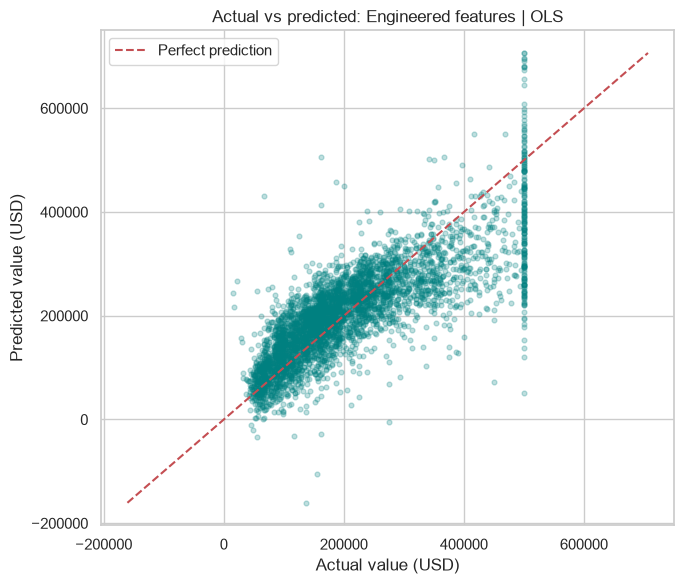

In [20]:
best_predictions = best_run["predictions"]
low = min(y_test.min(), best_predictions.min()); high = max(y_test.max(), best_predictions.max())
plt.figure(figsize=(7, 6))
plt.scatter(y_test, best_predictions, alpha=0.25, s=12, color="teal")
plt.plot([low, high], [low, high], "r--", label="Perfect prediction")
plt.title(f"Actual vs predicted: {best_name}"); plt.xlabel("Actual value (USD)"); plt.ylabel("Predicted value (USD)")
plt.legend(); plt.tight_layout(); plt.show()

## 21. Residual distributions

A residual is actual minus predicted value. A distribution centered near zero is desirable, while skew or a wide spread can indicate systematic error or uncertainty. The overlapping curves compare test residuals for all six model/feature-set combinations.

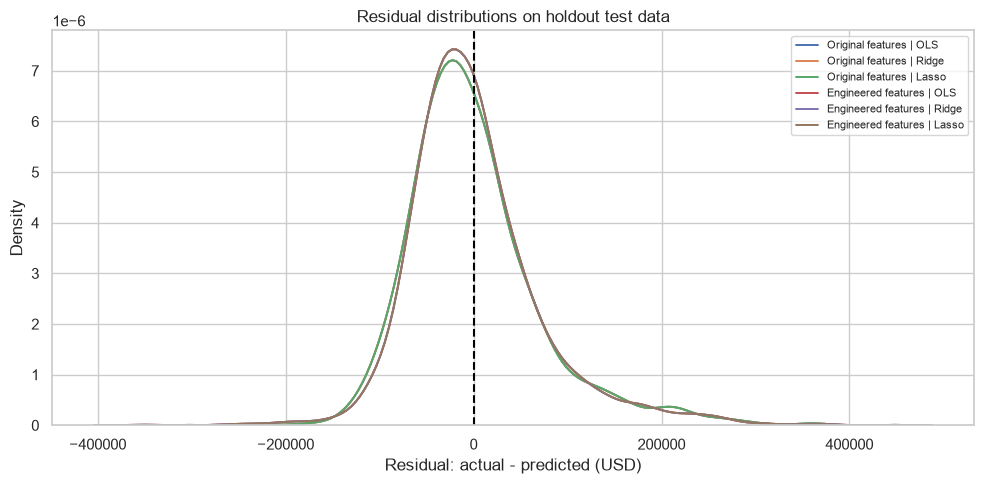

In [21]:
plt.figure(figsize=(10, 5))
for name, run in model_runs.items():
    residual = y_test.to_numpy() - run["predictions"]
    sns.kdeplot(residual, label=name, linewidth=1.4)
plt.axvline(0, color="black", linestyle="--")
plt.title("Residual distributions on holdout test data"); plt.xlabel("Residual: actual - predicted (USD)"); plt.ylabel("Density")
plt.legend(fontsize=8); plt.tight_layout(); plt.show()

## 22. Residuals versus predicted values

This plot checks whether errors change across the prediction range. A strong curve or widening pattern can indicate nonlinearity or unequal error variance; the horizontal zero line represents an exact prediction.

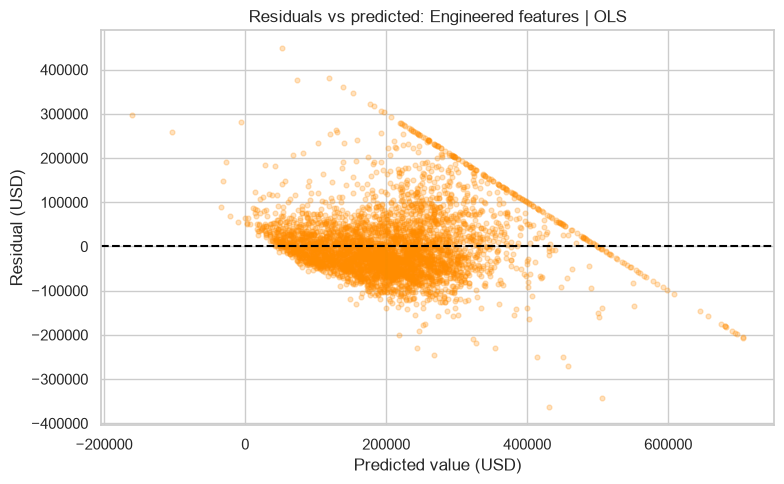

In [22]:
best_residuals = y_test.to_numpy() - best_predictions
plt.figure(figsize=(8, 5))
plt.scatter(best_predictions, best_residuals, alpha=0.25, s=12, color="darkorange")
plt.axhline(0, color="black", linestyle="--")
plt.title(f"Residuals vs predicted: {best_name}"); plt.xlabel("Predicted value (USD)"); plt.ylabel("Residual (USD)")
plt.tight_layout(); plt.show()

## 23. Model performance charts

The charts compare RMSE, MAE, and R? on the same holdout set. Lower is preferable for RMSE and MAE; higher is preferable for R?. These units and directions are labeled to avoid interpreting a visually larger bar as automatically better.

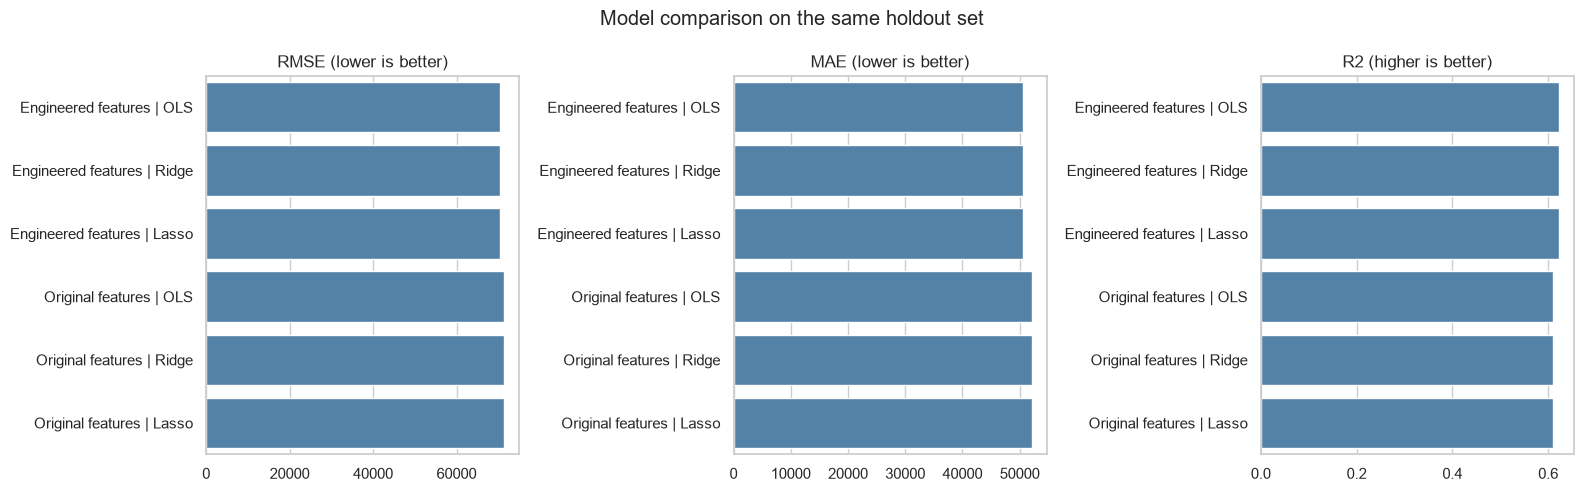

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, metric, higher_is_better in zip(axes, ["RMSE", "MAE", "R2"], [False, False, True]):
    ordered = comparison.sort_values(metric, ascending=not higher_is_better)
    sns.barplot(x=ordered[metric].values, y=ordered.index, ax=ax, color="steelblue")
    ax.set_title(f"{metric} ({'higher' if higher_is_better else 'lower'} is better)"); ax.set_ylabel("")
plt.suptitle("Model comparison on the same holdout set"); plt.tight_layout(); plt.show()

## 24. Report selected Ridge and Lasso alpha values

The reported alpha values are chosen by GridSearchCV using the training folds. The notebook lists each feature set separately so the selection process is transparent; the holdout results are not used to tune alpha.

In [24]:
for model_name in ["Ridge", "Lasso"]:
    for feature_set in ["Original features", "Engineered features"]:
        run = model_runs[f"{feature_set} | {model_name}"]
        cv_rmse = -run["estimator"].best_score_
        print(f"{model_name} on {feature_set}: GridSearchCV alpha = {run['alpha']:.6g}; 5-fold CV RMSE = {cv_rmse:,.2f} USD")

Ridge on Original features: GridSearchCV alpha = 1; 5-fold CV RMSE = 70,549.68 USD
Ridge on Engineered features: GridSearchCV alpha = 1; 5-fold CV RMSE = 68,677.25 USD
Lasso on Original features: GridSearchCV alpha = 10; 5-fold CV RMSE = 70,554.87 USD
Lasso on Engineered features: GridSearchCV alpha = 10; 5-fold CV RMSE = 68,682.03 USD


## 25. Identify important coefficients

Numeric coefficients are expressed per one standardized feature unit. A one-hot category coefficient is a contrast with its dropped reference category and should not be directly compared with numeric coefficients. Coefficients describe the fitted linear association, not causal effects.

For numeric features, coefficient magnitude indicates the modeled change per one standardized feature unit. A one-hot category coefficient is a contrast with the dropped reference category and is not directly comparable in scale to numeric coefficients. Signs show modeled direction, not causation.

                                Feature  Coefficient  Absolute coefficient
    categorical__ocean_proximity_ISLAND   122422.310            122422.310
                 numeric__median_income    77520.872             77520.872
                     numeric__longitude   -57912.781             57912.781
                      numeric__latitude   -57576.267             57576.267
                   numeric__total_rooms    39828.999             39828.999
    categorical__ocean_proximity_INLAND   -37017.729             37017.729
                    numeric__population   -34710.076             34710.076
             numeric__bedrooms_per_room    23420.722             23420.722
            numeric__housing_median_age    13775.720             13775.720
  categorical__ocean_proximity_NEAR BAY    -4252.028              4252.028
           numeric__rooms_per_household     4083.179              4083.179
categorical__ocean_proximity_NEAR OCEAN     3011.945              3011.945


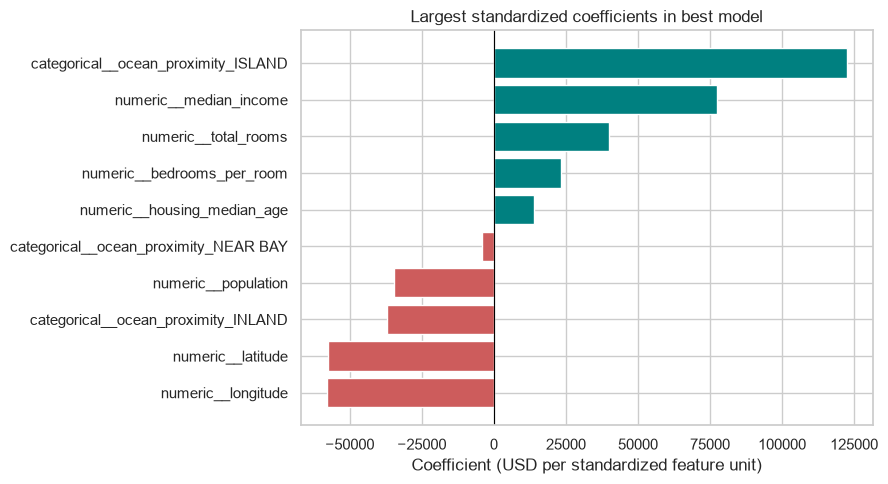

In [25]:
best_estimator = best_run["estimator"].best_estimator_ if isinstance(best_run["estimator"], GridSearchCV) else best_run["estimator"]
feature_names = best_estimator.named_steps["preprocessor"].get_feature_names_out()
coefficients = np.asarray(best_estimator.named_steps["regressor"].coef_).ravel()
importance = pd.DataFrame({"Feature": feature_names, "Coefficient": coefficients})
importance["Absolute coefficient"] = importance["Coefficient"].abs()
importance = importance.sort_values("Absolute coefficient", ascending=False)
print(importance.head(12).round(3).to_string(index=False))
plot_data = importance.head(10).sort_values("Coefficient")
plt.figure(figsize=(9, 5))
plt.barh(plot_data["Feature"], plot_data["Coefficient"], color=np.where(plot_data["Coefficient"] >= 0, "teal", "indianred"))
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Largest standardized coefficients in best model"); plt.xlabel("Coefficient (USD per standardized feature unit)")
plt.tight_layout(); plt.show()

## 26. Conclusion

The code below gathers the winning test result, the tuned regularization settings, and the largest coefficients from the fitted model. The interpretation should stay within this dataset and this train/test experiment, especially because the target is capped and geographic patterns may be nonlinear.

In [26]:
print(f"Best model by holdout RMSE: {best_name}")
print("Best model metrics: " + ", ".join(f"{key} = {value:,.3f}" for key, value in best_run["metrics"].items()))
for model_name in ["Ridge", "Lasso"]:
    tuned_run = model_runs[f"Engineered features | {model_name}"]
    print(f"{model_name} GridSearchCV alpha on engineered features: {tuned_run['alpha']:.6g}")
numeric_importance = importance[importance["Feature"].str.startswith("numeric__")]
categorical_importance = importance[importance["Feature"].str.startswith("categorical__")]
print("Largest continuous-feature coefficients (per standardized feature unit): " + ", ".join(numeric_importance.head(5)["Feature"].tolist()))
if not categorical_importance.empty:
    print("Largest category contrast: " + categorical_importance.iloc[0]["Feature"])
print("\nOLS is the unregularized baseline; Ridge shrinks coefficients, and Lasso can shrink coefficients to zero. RMSE and MAE are in dollars; R-squared summarizes explained variance.")
print("The selected model performed best among these candidates on the held-out data, but linear models cannot capture every nonlinear location and market pattern.")
print("The source target is area median value capped at $500,001, so predictions and conclusions should be interpreted with that limitation.")
print(f"Dataset was read only from {dataset_path}; the original CSV was not changed.")

Best model by holdout RMSE: Engineered features | OLS
Best model metrics: RMSE = 70,308.834, MAE = 50,594.977, R2 = 0.623
Ridge GridSearchCV alpha on engineered features: 1
Lasso GridSearchCV alpha on engineered features: 10
Largest continuous-feature coefficients (per standardized feature unit): numeric__median_income, numeric__longitude, numeric__latitude, numeric__total_rooms, numeric__population
Largest category contrast: categorical__ocean_proximity_ISLAND

OLS is the unregularized baseline; Ridge shrinks coefficients, and Lasso can shrink coefficients to zero. RMSE and MAE are in dollars; R-squared summarizes explained variance.
The selected model performed best among these candidates on the held-out data, but linear models cannot capture every nonlinear location and market pattern.
The source target is area median value capped at $500,001, so predictions and conclusions should be interpreted with that limitation.
Dataset was read only from C:\Users\usms.202300087\Datheon_Machine

## Student interpretation and limitations

In this run, **OLS with engineered features** had the lowest holdout RMSE among the six model/feature-set combinations: **$70,308.83 RMSE**, **$50,594.98 MAE**, and **0.623 R?**. The engineered-feature comparison improved on the original-feature OLS result (RMSE about **$71,466.83**, R? **0.610**). This suggests the household ratios provided useful information in this split, although the result should be confirmed with repeated evaluation before making a broad claim.

GridSearchCV selected **Ridge alpha = 1** and **Lasso alpha = 10** for the engineered feature set. These values were selected from training folds. Median income and geographic coordinates had some of the largest continuous-feature coefficients in the selected linear model; the ocean-proximity indicators are contrasts against a reference category. These are model associations, not causal explanations.

The residual and actual-versus-predicted plots help show that error remains substantial even for the best candidate. Linear models do not fully represent complex spatial relationships, and the target's $500,001 cap limits interpretation at the top end. A natural next step would be to compare with a nonlinear model and evaluate across repeated splits, while preserving a final untouched test set.